# 09 - Weather normalisation of PM2.5 and the PM seasonal management system (미세먼지 계절관리제)

**Question.** How much of the change in Seoul's PM2.5 since 2015 remains once the weather of each day is removed, and are the seasons of the PM seasonal management system (December to March, every year since December 2019) lower than the earlier seasons by more than the long-term decline, COVID-19 and the regional background would suggest?

**Approach.**
1. A gradient boosting model learns the daily city PM2.5 (mean of the 25 urban stations, notebook 07) from the ERA5 weather of the day and of the day before (notebook 08), the time of year, the weekday and a time variable. It is validated by time: each year is predicted by a model that never saw it, and also by models fit only on earlier years.
2. Weather normalisation: each day is predicted 200 times with the weather of other days from the same part of the year (within 15 days of its date, any year) and the predictions are averaged. The result keeps the seasonal cycle and the long-term change but not the weather of that particular day. Ten models fit on block-bootstrap samples measure the uncertainty that comes from the model.
3. The seasons before (2015-16 to 2018-19) and after (2019-20 to 2024-25) December 2019 are compared in four ways, each of which removes a different alternative explanation: a plain before-after difference, a gap from the earlier trend, a difference in differences against the April-November months of the same years, and the exclusion of the COVID-19 seasons. The regional background station of Baengnyeong Island gives the regional context.

**Limits of the design.** The system started in all of Korea at the same time, so there is no untreated region to compare with; COVID-19 began in its first season; China's emissions also fell in these years. None of the comparisons isolates the system, so the results are described as associations, and the conclusion says which explanations each comparison does and does not remove.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

from seoul_air import config, deweather, policy, trend
from seoul_air.report import save_key_figures

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 1. Data

In [2]:
air = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet")
city = air.groupby("date")["pm25"].mean()
city.index = pd.DatetimeIndex(city.index)
weather_daily = pd.read_parquet(config.DATA_PROCESSED / "weather_daily_2015_2025.parquet")
weather_daily["date"] = pd.to_datetime(weather_daily["date"])
table = deweather.build_table(city, weather_daily)
print("Days:", len(table), "| from", table.index.min().date(), "to", table.index.max().date())
print("Features:", len(deweather.features(table)), "=", len(deweather.weather_features(table)), "weather +",
      len(deweather.TIME_COLUMNS), "time")
missing = table.isna().sum()
print("Missing values (left missing, the model handles them):")
print(missing[missing > 0].to_string())

Days: 4018 | from 2015-01-01 to 2025-12-31
Features: 20 = 16 weather + 4 time
Missing values (left missing, the model handles them):
boundary_layer_height_mean_m         183
boundary_layer_height_max_m          183
precipitation_mm_lag1                  1
wind_speed_mean_ms_lag1                1
boundary_layer_height_mean_m_lag1    184
temperature_mean_c_lag1                1
relative_humidity_mean_pct_lag1        1


**Interpretation.** The table has 4018 days, from 2015-01-01 to 2025-12-31, and 20 inputs: 16 weather inputs (the day and, for five variables, the day before) and 4 date inputs. The boundary layer height is missing on 183 days (January to June 2024, notebook 08). Gradient boosting handles missing values, so these days are kept and no row is removed.

## 2. Validation by time

Three versions of the model are compared with a model that knows only the date (time of year, weekday, time variable), which is the seasonal baseline: the gain over it is what the weather adds. Two schemes keep the predicted year out of the fit:
- **Leave one year out**: each year is predicted by a model fit on the other ten. This is the setting of the normalisation, which uses all years.
- **Forward chaining**: each year from 2018 is predicted by a model fit only on the earlier years, a stricter check that the relation with the weather holds for years not yet seen.

The settings are chosen by the forward-chaining MAE.

In [3]:
settings = {
    "small": {"max_iter": 200, "learning_rate": 0.05, "max_leaf_nodes": 15, "min_samples_leaf": 40},
    "default": {"max_iter": 400, "learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 20},
    "large": {"max_iter": 800, "learning_rate": 0.03, "max_leaf_nodes": 63, "min_samples_leaf": 20},
}
date_only = table[["pm25"] + deweather.TIME_COLUMNS]
baseline_loyo = deweather.leave_one_year_out(date_only)
baseline_forward = deweather.forward_chaining(date_only, 2018)
rows = {}
predictions = {}
for name, params in settings.items():
    predictions[name] = (deweather.leave_one_year_out(table, params), deweather.forward_chaining(table, 2018, params))
for name, (loyo, forward) in {"date only": (baseline_loyo, baseline_forward), **predictions}.items():
    for scheme, pred in [("leave one year out", loyo), ("forward chaining", forward)]:
        rows[(name, scheme)] = deweather.score_by_year(table["pm25"], pred).loc["all"]
validation = pd.DataFrame(rows).T
print(validation.round(3).to_string())
chosen = validation.xs("forward chaining", level=1).drop("date only")["mae"].idxmin()
params = settings[chosen]
print("Chosen settings:", chosen, params)

                                days     r2    mae   bias
date only leave one year out  4018.0  0.069  9.466  0.093
          forward chaining    2922.0 -0.022  9.847 -0.704
small     leave one year out  4018.0  0.479  6.767  0.739
          forward chaining    2922.0  0.510  6.483  0.392
default   leave one year out  4018.0  0.495  6.622  0.423
          forward chaining    2922.0  0.474  6.892  0.996
large     leave one year out  4018.0  0.493  6.640  0.394
          forward chaining    2922.0  0.460  7.004  1.137
Chosen settings: small {'max_iter': 200, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 40}


Leave one year out, by year:
     weather model                    date only                   
              days    r2    mae  bias      days    r2    mae  bias
date                                                              
2015         365.0  0.33   6.75  1.76     365.0 -0.13   9.66  2.32
2016         366.0  0.34   6.87 -1.35     366.0 -0.11   9.31 -0.65
2017         365.0  0.57   6.66 -0.03     365.0  0.08  10.22  0.81
2018         365.0  0.16  11.84  9.98     365.0  0.07  10.82  2.58
2019         365.0  0.45   7.61 -3.22     365.0  0.05  10.84 -3.87
2020         366.0  0.62   5.19 -0.50     366.0  0.09   8.59 -1.37
2021         365.0  0.52   6.61  1.97     365.0  0.13   9.44  0.46
2022         365.0  0.56   5.45  0.95     365.0  0.05   8.49  1.89
2023         365.0  0.54   5.98 -0.14     365.0  0.12   8.54 -1.39
2024         366.0  0.38   5.72 -0.71     366.0 -0.31   9.33  1.34
2025         365.0  0.59   5.76 -0.57     365.0  0.02   8.89 -1.10
all         4018.0  0.48   6.77  

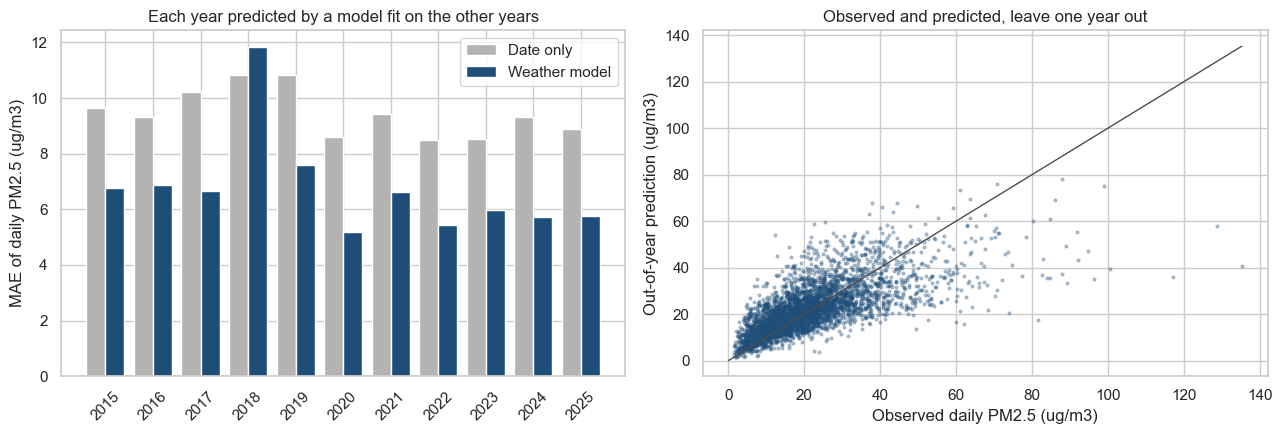

In [4]:
loyo, forward = predictions[chosen]
by_year = pd.concat({"weather model": deweather.score_by_year(table["pm25"], loyo),
                     "date only": deweather.score_by_year(table["pm25"], baseline_loyo)}, axis=1)
print("Leave one year out, by year:")
print(by_year.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
years = by_year.index[by_year.index != "all"]
x = np.arange(len(years))
axes[0].bar(x - 0.2, by_year.loc[years, ("date only", "mae")], 0.4, color="0.7", label="Date only")
axes[0].bar(x + 0.2, by_year.loc[years, ("weather model", "mae")], 0.4, color="#1f4e79", label="Weather model")
axes[0].set_xticks(x, years, rotation=45)
axes[0].set_ylabel("MAE of daily PM2.5 (ug/m3)")
axes[0].set_title("Each year predicted by a model fit on the other years")
axes[0].legend()
axes[1].scatter(table["pm25"], loyo, s=4, alpha=0.3, color="#1f4e79")
lim = [0, float(table["pm25"].max())]
axes[1].plot(lim, lim, color="0.3", lw=1)
axes[1].set_xlabel("Observed daily PM2.5 (ug/m3)")
axes[1].set_ylabel("Out-of-year prediction (ug/m3)")
axes[1].set_title("Observed and predicted, leave one year out")
fig.tight_layout()
fig.savefig(config.FIGURES / "09_validation.png", dpi=150)
plt.show()

**Interpretation.** The weather adds a large part of what the date alone cannot explain: leaving each year out, R2 rises from 0.069 (date only) to 0.479 and the MAE falls from 9.466 to 6.767 ug/m3. Forward chaining, which predicts each year from 2018 with only the earlier years, gives R2 0.510 and MAE 6.483, so the relation with the weather holds for years the model has not seen. The three settings differ little; the small one has the lowest forward-chaining MAE and is used from here on. About half of the daily variance remains unexplained: emissions, transport not captured by one grid point, and episodes are not in the inputs. The worst year is 2018 (R2 0.16, bias 9.98 ug/m3): a model fit on the other years predicts it higher than observed, so 2018 was cleaner than its weather and the level of the neighbouring years suggest.

Which inputs matter: permutation importance on 2025, predicted by a model fit on 2015-2024 (the drop in R2 when one input is shuffled).

doy_sin                              0.305
boundary_layer_height_mean_m_lag1    0.101
precipitation_mm_lag1                0.078
boundary_layer_height_mean_m         0.069
doy_cos                              0.069
relative_humidity_mean_pct           0.064
wind_u_mean_ms                       0.061
temperature_mean_c_lag1              0.054
wind_v_mean_ms                       0.041
temperature_min_c                    0.029
Sum over weather inputs: 0.582 | sum over date inputs: 0.369


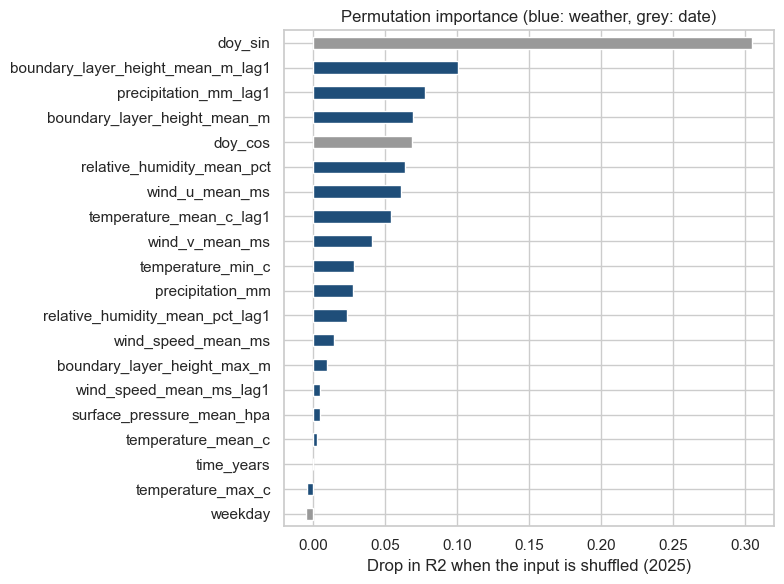

In [5]:
train, test = table.index.year < 2025, table.index.year == 2025
model_2025 = deweather.make_model(**params).fit(table.loc[train, deweather.features(table)], table.loc[train, "pm25"])
importance = permutation_importance(model_2025, table.loc[test, deweather.features(table)], table.loc[test, "pm25"],
                                    n_repeats=10, random_state=0, scoring="r2")
importance = pd.Series(importance.importances_mean, index=deweather.features(table)).sort_values()
print(importance.sort_values(ascending=False).round(3).head(10).to_string())
is_weather = importance.index.isin(deweather.weather_features(table))
print("Sum over weather inputs:", round(importance[is_weather].sum(), 3),
      "| sum over date inputs:", round(importance[~is_weather].sum(), 3))
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax, color=["#1f4e79" if c in deweather.weather_features(table) else "0.6" for c in importance.index])
ax.set_xlabel("Drop in R2 when the input is shuffled (2025)")
ax.set_title("Permutation importance (blue: weather, grey: date)")
fig.tight_layout()
fig.savefig(config.FIGURES / "09_importance.png", dpi=150)
plt.show()

**Interpretation.** On 2025, shuffling the weather inputs one at a time lowers R2 by 0.582 in total, against 0.369 for the date inputs; the largest single input is the time of year (doy_sin, 0.305). Among the weather inputs, the boundary layer height of the day before (0.101), the precipitation of the day before (0.078) and the boundary layer height of the day (0.069) lead. This agrees with the expected roles of vertical mixing and wet removal, and the weight of the day before agrees with PM2.5 building up over several days. Correlated inputs share their importance, so the ranking within the weather inputs is indicative only.

## 3. Weather-normalised PM2.5

The main model is fit on all days with the chosen settings. Ten more models, each fit on a resample of 30-day blocks of days, give the model uncertainty: the shaded band is their range.

In [6]:
N_SAMPLES, WINDOW_DAYS, N_MODELS, BLOCK_DAYS = 200, 15, 10, 30
main_model = deweather.make_model(**params).fit(table[deweather.features(table)], table["pm25"])
normalised = deweather.normalise(main_model, table, n_samples=N_SAMPLES, window_days=WINDOW_DAYS, seed=0)
members = deweather.normalised_ensemble(table, n_models=N_MODELS, block_days=BLOCK_DAYS, params=params, seed=1,
                                        n_samples=N_SAMPLES, window_days=WINDOW_DAYS)
print("Weather draws per day:", N_SAMPLES, "| calendar window: +/-", WINDOW_DAYS, "days | bootstrap models:",
      members.shape[1], "| block length:", BLOCK_DAYS, "days")
monthly_obs = trend.monthly_means(table["pm25"])
monthly_norm = trend.monthly_means(normalised)
monthly_members = members.apply(trend.monthly_means)
print("Months:", len(monthly_obs), "| members:", members.shape[1])
weather_part = (monthly_obs - monthly_norm)
print("Weather contribution (observed minus normalised), monthly, ug/m3:")
print(weather_part.describe().round(2).to_string())

Weather draws per day: 200 | calendar window: +/- 15 days | bootstrap models: 10 | block length: 30 days
Months: 132 | members: 10
Weather contribution (observed minus normalised), monthly, ug/m3:
count    132.00
mean       0.02
std        2.80
min       -6.17
25%       -1.94
50%       -0.22
75%        1.73
max       12.26


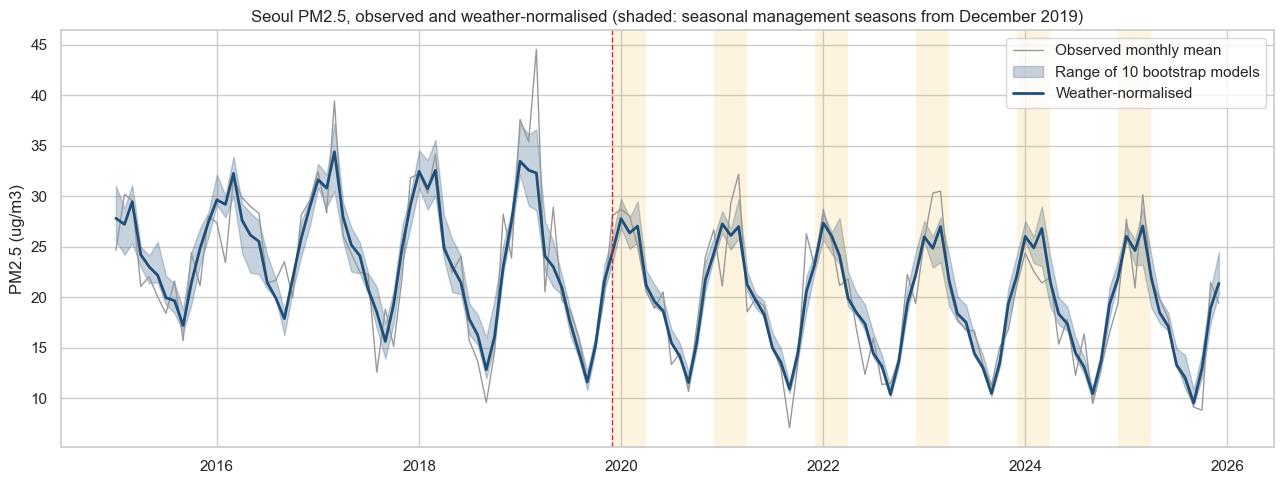

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
t = monthly_obs.index.to_timestamp()
ax.plot(t, monthly_obs, color="0.6", lw=1, label="Observed monthly mean")
ax.fill_between(t, monthly_members.min(axis=1), monthly_members.max(axis=1), color="#1f4e79", alpha=0.25,
                label="Range of 10 bootstrap models")
ax.plot(t, monthly_norm, color="#1f4e79", lw=2, label="Weather-normalised")
for season in range(2019, 2025):
    ax.axvspan(pd.Timestamp(f"{season}-12-01"), pd.Timestamp(f"{season + 1}-03-31"), color="#f2a900", alpha=0.12, lw=0)
ax.axvline(pd.Timestamp("2019-12-01"), color="#d62728", ls="--", lw=1)
ax.set_ylabel("PM2.5 (ug/m3)")
ax.set_title("Seoul PM2.5, observed and weather-normalised (shaded: seasonal management seasons from December 2019)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(config.FIGURES / "09_normalised_monthly.png", dpi=150)
plt.show()

Long-term trend of the observed and the normalised series (Theil-Sen slope of deseasonalised monthly means, 12-month block bootstrap, as in notebook 02).

In [8]:
trends = pd.DataFrame({"observed": trend.trend(monthly_obs, n_boot=2000),
                       "weather-normalised": trend.trend(monthly_norm, n_boot=2000)}).T
member_slopes = [trend.theil_sen(trend.years_since_start(trend.deseasonalise(monthly_members[m]).dropna().index),
                                 trend.deseasonalise(monthly_members[m]).dropna().to_numpy())[0]
                 for m in monthly_members]
print(trends[["slope_per_year", "low_95", "high_95", "pct_per_year", "pct_low_95", "pct_high_95"]].astype(float).round(2).to_string())
print("Normalised slope across the 10 bootstrap models: from", round(min(member_slopes), 2), "to",
      round(max(member_slopes), 2), "ug/m3 per year")

                    slope_per_year  low_95  high_95  pct_per_year  pct_low_95  pct_high_95
observed                     -0.76   -0.97    -0.54         -3.53       -4.54        -2.52
weather-normalised           -0.70   -0.88    -0.50         -3.24       -4.09        -2.35
Normalised slope across the 10 bootstrap models: from -0.79 to -0.61 ug/m3 per year


**Interpretation.** Removing the weather changes the long-term trend little: -0.70 ug/m3 per year (95% interval -0.88 to -0.50, -3.24% per year) after normalisation against -0.76 (-0.97 to -0.54) observed, and the ten bootstrap models give slopes from -0.79 to -0.61. The weather of 2015-2025 therefore does not explain the decline. It matters month to month: the observed monthly mean differs from the normalised one with a standard deviation of 2.80 ug/m3 and by up to 12.26 ug/m3.

## 4. Seasons before and after December 2019

A season is December to March and is named by the year of its December (2019 = December 2019 to March 2020). Only complete seasons count: 2015 to 2024, four before the system and six with it. The months of January to March 2015 (no December 2014) and December 2025 are left out.

In [9]:
seasons = pd.DataFrame({"observed": policy.season_means(monthly_obs),
                        "normalised": policy.season_means(monthly_norm)})
seasons["weather part"] = seasons["observed"] - seasons["normalised"]
member_seasons = monthly_members.apply(policy.season_means)
seasons["members min"] = member_seasons.min(axis=1)
seasons["members max"] = member_seasons.max(axis=1)
seasons["period"] = np.where(seasons.index >= policy.FIRST_SEASON, "with the system", "before")
print(seasons.round(2).to_string())
others = pd.DataFrame({"observed": policy.other_months_means(monthly_obs),
                       "normalised": policy.other_months_means(monthly_norm)})
print()
print("April-November of each year:")
print(others.round(2).to_string())

      observed  normalised  weather part  members min  members max           period
2015     27.67       29.63         -1.97        29.02        30.73           before
2016     32.44       31.43          1.01        30.20        32.64           before
2017     32.14       31.24          0.90        30.27        33.50           before
2018     35.37       31.47          3.90        29.26        33.64           before
2019     27.49       26.43          1.07        25.69        28.30  with the system
2020     27.34       26.18          1.15        25.69        27.64  with the system
2021     24.59       25.20         -0.61        24.17        26.09  with the system
2022     26.48       25.02          1.46        23.94        26.21  with the system
2023     22.37       24.95         -2.58        23.92        25.78  with the system
2024     24.55       24.90         -0.35        23.93        25.73  with the system

April-November of each year:
      observed  normalised
date               

**Interpretation.** Before the system, the normalised seasons lie between 29.63 and 31.47 ug/m3; with it, between 24.90 and 26.43. The largest step is between the 2018 and 2019 seasons (31.47 to 26.43), and the later seasons continue to fall slowly. The 2018 season (December 2018 to March 2019, with the March 2019 episodes) was the highest observed season (35.37), and 3.90 ug/m3 of it is attributed to the weather; the 2023 season was helped by the weather (-2.58). The months outside the system also fell: normalised April-November means were 21.57 to 23.29 in 2015-2017 and 15.54 to 17.23 in 2020-2025.

## 5. Four comparisons

- **A. Before-after**: mean of the six seasons with the system minus the mean of the four before. It removes nothing but the weather (in the normalised series); the long-term decline alone produces a negative value. The p-value is exact: the share of the 210 ways of choosing six of the ten seasons that give a difference at least as large.
- **B. Gap from the earlier trend**: the same difference minus the change expected if the deseasonalised trend of January 2015 to November 2019 had continued. It removes a steady decline, but the pre-period is short (59 months), so the interval includes the uncertainty of that slope.
- **C. Difference in differences**: the change in the seasons minus the change in the April-November months that follow each season. The months outside the system share the long-term decline, COVID-19 and year-round regional and national changes, but not changes specific to the cold season. It is computed in ug/m3 and in logarithms (relative change), because the same relative decline is a larger absolute one in winter.
- **D. COVID-19**: A to C again without the seasons 2019 and 2020, the two seasons with the largest COVID-19 changes in activity (February 2020 onwards).

Every comparison is computed on the main normalised series and on each of the ten bootstrap models (model range).

In [10]:
def compare(monthly, exclude=()):
    season = policy.season_means(monthly).drop(list(exclude), errors="ignore")
    other = policy.other_months_means(monthly)
    a = policy.before_after(season)
    b = policy.trend_gap(trend.deseasonalise(monthly), season, n_boot=2000)
    c_abs = policy.before_after(policy.season_minus_other(season, other))
    c_log = policy.before_after(policy.season_minus_other(season, other, log=True))
    return {
        "A before-after (ug/m3)": a["difference"], "A p-value": a["p_value"],
        "B gap from trend (ug/m3)": b["gap"], "B low 95": b["gap_low_95"], "B high 95": b["gap_high_95"],
        "B pre-period slope (ug/m3/yr)": b["pre_slope_per_year"], "B pre-period months": b["pre_months"],
        "C diff-in-diff (ug/m3)": c_abs["difference"], "C p-value": c_abs["p_value"],
        "C diff-in-diff (% relative)": 100 * (np.exp(c_log["difference"]) - 1), "C log p-value": c_log["p_value"],
        "seasons before/with": f"{a['pre_seasons']}/{a['post_seasons']}",
    }


cases = {
    ("observed", "all seasons"): compare(monthly_obs),
    ("normalised", "all seasons"): compare(monthly_norm),
    ("observed", "without 2019-2020"): compare(monthly_obs, exclude=(2019, 2020)),
    ("normalised", "without 2019-2020"): compare(monthly_norm, exclude=(2019, 2020)),
}
comparisons = pd.DataFrame(cases)
numeric = ["A before-after (ug/m3)", "B gap from trend (ug/m3)", "C diff-in-diff (ug/m3)", "C diff-in-diff (% relative)"]
for exclude, label in [((), "all seasons"), ((2019, 2020), "without 2019-2020")]:
    member_results = pd.DataFrame({m: compare(monthly_members[m], exclude) for m in monthly_members}).loc[numeric]
    comparisons[("model range", label)] = [
        f"{member_results.loc[k].astype(float).min():.2f} to {member_results.loc[k].astype(float).max():.2f}"
        if k in numeric else "" for k in comparisons.index]
shown = comparisons.copy().astype(object)
for key in shown.index:
    digits = 3 if "p-value" in key else (0 if "months" in key else 2)
    shown.loc[key] = [f"{v:.{digits}f}" if isinstance(v, float) else v for v in shown.loc[key]]
print(shown.to_string())
print("Ways of choosing the seasons with the system among all complete seasons:", math.comb(10, 6))

                                 observed  normalised          observed        normalised     model range                  
                              all seasons all seasons without 2019-2020 without 2019-2020     all seasons without 2019-2020
A before-after (ug/m3)              -6.43       -5.50             -7.41             -5.93  -6.99 to -4.51    -7.73 to -4.77
A p-value                           0.005       0.005             0.029             0.029                                  
B gap from trend (ug/m3)            -5.34       -2.70             -6.09             -2.57  -5.30 to -0.24     -5.72 to 0.44
B low 95                            -9.34       -5.21            -10.89             -5.58                                  
B high 95                           -1.13       -0.44             -1.04              0.14                                  
B pre-period slope (ug/m3/yr)       -0.22       -0.56             -0.22             -0.56                                  
B pre-pe

**Interpretation.** A. The normalised seasons with the system are 5.50 ug/m3 lower than before (observed: 6.43), with p = 0.005: no other way of splitting the ten seasons gives as large a difference. This removes the weather but not the long-term decline. B. Against the earlier trend, the normalised gap is -2.70 ug/m3 (-5.21 to -0.44). The pre-period slope is uncertain (59 months) and depends on the weather: -0.56 ug/m3 per year normalised but -0.22 observed, because the weather of the 2018 season raised the end of the observed pre-period; the observed gap (-5.34) is therefore larger. Without the 2019 and 2020 seasons the normalised gap is similar (-2.57) but its interval (-5.58 to 0.14) includes zero. C. Against the April-November months, the difference in differences is -0.89 ug/m3 (p = 0.405) and, in relative terms, +5.19% (p = 0.386): the seasons fell by more ug/m3 than the other months, but not by a larger share, and neither difference is distinguishable from the year-to-year variation. D. Excluding the two COVID-19 seasons keeps A and C as they are and widens the interval of B to include zero. The model ranges are wide for B (-5.30 to -0.24) and C (-2.33 to 8.51%), so the choice of model alone moves these estimates by an amount similar to their size.

A placebo check of comparison B: the same trend gap for the April-November months, which the system does not cover. If those months also fall below the earlier trend by a similar amount, the gap in the seasons is not specific to them.

In [11]:
other_as_seasons = lambda monthly: policy.other_months_means(monthly).rename(lambda year: year - 1)  # noqa: E731
placebo = pd.DataFrame({
    name: policy.trend_gap(trend.deseasonalise(monthly), other_as_seasons(monthly), n_boot=2000)
    for name, monthly in [("observed", monthly_obs), ("normalised", monthly_norm)]
}).T[["before_after", "expected_change", "gap", "gap_low_95", "gap_high_95"]]
print("Trend gap of April-November (2020-2025 against 2016-2019, ug/m3):")
print(placebo.astype(float).round(2).to_string())

Trend gap of April-November (2020-2025 against 2016-2019, ug/m3):
            before_after  expected_change   gap  gap_low_95  gap_high_95
observed           -4.76            -1.21 -3.55       -7.95         1.08
normalised         -4.75            -3.08 -1.67       -4.43         0.81


**Interpretation.** April-November, which the system does not cover, also fell below its earlier trend: normalised gap -1.67 ug/m3 (-4.43 to 0.81), observed -3.55 (-7.95 to 1.08). A gap of the same sign outside the seasons means that comparison B alone cannot be read as specific to the seasonal management system: part of the gap is a faster decline of the whole year after 2019.

## 6. Regional context: Baengnyeong Island

Baengnyeong Island (백령도) is the national background station in the Yellow Sea, west of Seoul and upwind of it in the cold season; its PM2.5 reflects the regional and transboundary air reaching Korea with little influence of Seoul's own emissions. Monthly means for 2018-2024 come from the AirKorea final data (`tools/regional_background.py`; only monthly means are stored because the final data is licensed under KOGL Type 3). The Seoul column there is the mean of the same 25 urban stations in the final data, so it is comparable with Baengnyeong but not identical to the provisional series above. Only one complete season (2018) is before the system.

In [12]:
regional = pd.read_csv(config.ROOT / "data" / "reference" / "baengnyeong_seoul_monthly_2018_2024.csv")
regional.index = pd.PeriodIndex(regional["month"], freq="M")
print("Months with both values:", int(regional[["seoul", "baengnyeong"]].notna().all(axis=1).sum()), "of", len(regional))
regional_seasons = pd.DataFrame({site: policy.season_means(regional[site]) for site in ["seoul", "baengnyeong"]})
regional_seasons["seoul minus baengnyeong"] = regional_seasons["seoul"] - regional_seasons["baengnyeong"]
regional_seasons["seoul / baengnyeong"] = regional_seasons["seoul"] / regional_seasons["baengnyeong"]
print(regional_seasons.round(2).to_string())
regional_other = pd.DataFrame({site: policy.other_months_means(regional[site]) for site in ["seoul", "baengnyeong"]})
regional_other["seoul / baengnyeong"] = regional_other["seoul"] / regional_other["baengnyeong"]
print()
print("April-November:")
print(regional_other.round(2).to_string())
both = regional[["seoul", "baengnyeong"]].dropna()
anomalies = both.apply(trend.deseasonalise)
print()
print("Correlation of monthly means:", round(both.corr().iloc[0, 1], 2),
      "| of deseasonalised monthly anomalies:", round(anomalies.corr().iloc[0, 1], 2))
regional_trends = pd.DataFrame({site: trend.trend(regional[site].dropna(), n_boot=2000)
                                for site in ["seoul", "baengnyeong"]}).T
print(regional_trends[["months", "slope_per_year", "low_95", "high_95", "pct_per_year"]].astype(float).round(2).to_string())

Months with both values: 78 of 84
      seoul  baengnyeong  seoul minus baengnyeong  seoul / baengnyeong
2018  35.34        27.83                     7.51                 1.27
2019  27.48        23.29                     4.19                 1.18
2020  27.33        26.35                     0.98                 1.04
2021  24.59        19.17                     5.43                 1.28
2022  26.47        21.33                     5.14                 1.24
2023  22.37        21.11                     1.26                 1.06

April-November:
       seoul  baengnyeong  seoul / baengnyeong
month                                         
2018   19.23        14.37                 1.34
2019   18.81        15.65                 1.20
2020   17.45        16.73                 1.04
2021   16.53        18.34                 0.90
2022   15.74          NaN                  NaN
2023   16.11        16.31                 0.99
2024   15.34        14.00                 1.10

Correlation of monthly means

             months  slope_per_year  low_95  high_95  pct_per_year
seoul          84.0           -0.85   -1.13    -0.58         -4.13
baengnyeong    78.0           -0.39   -0.75    -0.06         -2.07


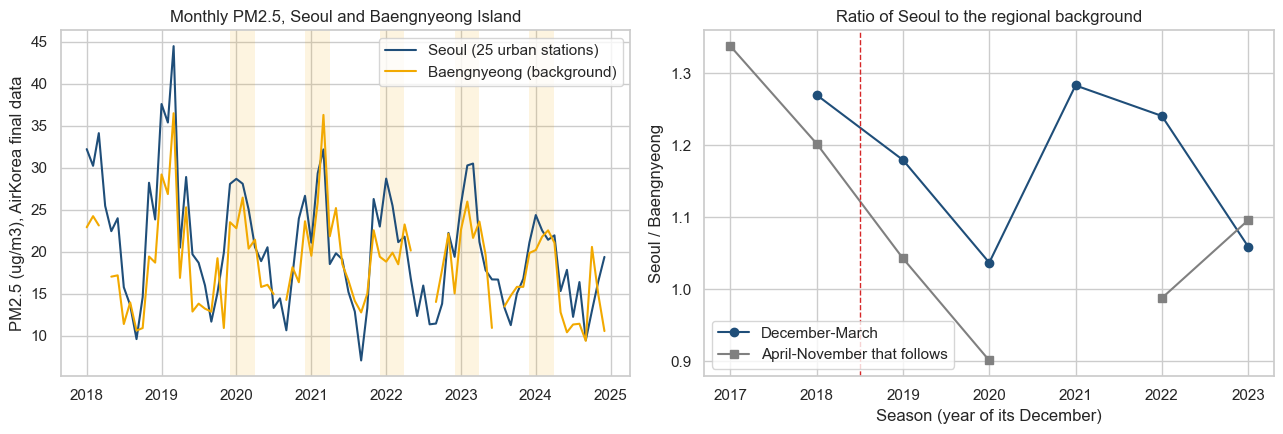

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
t = regional.index.to_timestamp()
axes[0].plot(t, regional["seoul"], color="#1f4e79", lw=1.5, label="Seoul (25 urban stations)")
axes[0].plot(t, regional["baengnyeong"], color="#f2a900", lw=1.5, label="Baengnyeong (background)")
for season in range(2019, 2024):
    axes[0].axvspan(pd.Timestamp(f"{season}-12-01"), pd.Timestamp(f"{season + 1}-03-31"), color="#f2a900", alpha=0.12, lw=0)
axes[0].set_ylabel("PM2.5 (ug/m3), AirKorea final data")
axes[0].set_title("Monthly PM2.5, Seoul and Baengnyeong Island")
axes[0].legend()
axes[1].plot(regional_seasons.index, regional_seasons["seoul / baengnyeong"], marker="o", color="#1f4e79",
             label="December-March")
axes[1].plot(regional_other.index - 1, regional_other["seoul / baengnyeong"], marker="s", color="0.5",
             label="April-November that follows")
axes[1].axvline(2018.5, color="#d62728", ls="--", lw=1)
axes[1].set_xlabel("Season (year of its December)")
axes[1].set_ylabel("Seoul / Baengnyeong")
axes[1].set_title("Ratio of Seoul to the regional background")
axes[1].legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "09_regional_context.png", dpi=150)
plt.show()

**Interpretation.** Seoul and Baengnyeong move together: the correlation of monthly means is 0.81 and of deseasonalised anomalies 0.65 (78 of 84 months with both values), so a large part of Seoul's month-to-month variation is regional. From 2018 to 2024 Seoul declined faster than the background: -0.85 ug/m3 per year (-1.13 to -0.58, -4.13% per year) against -0.39 (-0.75 to -0.06, -2.07% per year), which leaves room for a domestic contribution to the decline. The ratio of Seoul to Baengnyeong does not show a step specific to the seasons: in December-March it was 1.27 in 2018, then 1.18, 1.04, 1.28, 1.24 and 1.06; in April-November it fell from 1.34 in 2018 to between 0.90 and 1.20 later. With a single complete season before the system (2018), the regional gap before the system cannot be estimated from these data.

## 7. Comparison with published studies

The two studies use different data and designs; the table summarises what their abstracts report (verified on Europe PMC), next to the results of this notebook.

In [14]:
literature = pd.DataFrame([
    {"study": "Lee et al. (2024), Sci. Total Environ. 920, 170822",
     "data": "Seoul and Baengnyeong, hourly PM2.5 and its components, 2015-2021",
     "method": "Weather normalisation (machine learning) and the GEOS-Chem chemical transport model",
     "reported": "Annual decline larger in Seoul than in Baengnyeong (abstract: '-0.7 vs -1.8 ug/m3 per year', quoted as published); "
                 "attributed to local policies including the Special Act on the Seoul Metropolitan Area and the seasonal control "
                 "measures; normalised PM2.5 highest in March, lowest in August, nitrate about 40% of that difference"},
    {"study": "Ryoo et al. (2024), Environ. Int. 191, 108970",
     "data": "Seoul and Beijing filter samples: Jan-Dec 2019, Sep 2020-May 2021, Jul 2021-Mar 2022",
     "method": "Dispersion-normalised positive matrix factorisation (DN-PMF), source apportionment",
     "reported": "In Seoul the seasonal management programs were associated with significantly lower PM2.5 mass and "
                 "contributions of motor vehicles, residual oil, industry, coal and biomass burning (p < 0.05), after accounting "
                 "for dispersion and with COVID-19 considered; secondary nitrate was the largest source (8.67 ug/m3, 34%)"},
    {"study": "This notebook",
     "data": "Seoul, 25 urban stations, daily PM2.5 2015-2025 (provisional official data); Baengnyeong monthly 2018-2024",
     "method": "Gradient boosting weather normalisation, validated by year; four season comparisons",
     "reported": "see the conclusion below"},
]).set_index("study")
for study, row in literature.iterrows():
    print(study)
    for field, text in row.items():
        print(f"  {field}: {text}")
    print()

Lee et al. (2024), Sci. Total Environ. 920, 170822
  data: Seoul and Baengnyeong, hourly PM2.5 and its components, 2015-2021
  method: Weather normalisation (machine learning) and the GEOS-Chem chemical transport model
  reported: Annual decline larger in Seoul than in Baengnyeong (abstract: '-0.7 vs -1.8 ug/m3 per year', quoted as published); attributed to local policies including the Special Act on the Seoul Metropolitan Area and the seasonal control measures; normalised PM2.5 highest in March, lowest in August, nitrate about 40% of that difference

Ryoo et al. (2024), Environ. Int. 191, 108970
  data: Seoul and Beijing filter samples: Jan-Dec 2019, Sep 2020-May 2021, Jul 2021-Mar 2022
  method: Dispersion-normalised positive matrix factorisation (DN-PMF), source apportionment
  reported: In Seoul the seasonal management programs were associated with significantly lower PM2.5 mass and contributions of motor vehicles, residual oil, industry, coal and biomass burning (p < 0.05), after 

**Interpretation.** Lee et al. (2024) also find a faster decline in Seoul than at Baengnyeong, which agrees with the 2018-2024 slopes above; the abstract gives the two rates in an order that seems to contradict its sentence, so they are quoted as published and not compared numerically. Ryoo et al. (2024) report significant reductions in the seasonal management periods in PM2.5 mass and in source contributions linked to combustion. Both studies attribute part of the decline to policy using information this notebook does not have (chemical composition, source profiles, a chemical transport model). With PM2.5 mass and weather alone, the results here are consistent with lower PM2.5 in the seasons, but they cannot separate the system from the decline of the whole year; the two findings do not contradict each other, because measures of the system that act on emissions with effects across months would not show up as a season-specific difference.

## 8. Key figures

In [15]:
def as_float(case, key):
    return float(comparisons.loc[key, case])


save_key_figures("09", {
    "chosen_settings": chosen,
    "validation": {f"{name} | {scheme}": validation.loc[(name, scheme)].to_dict() for name, scheme in validation.index},
    "trend": {name: trends.loc[name, ["slope_per_year", "low_95", "high_95", "pct_per_year", "pct_low_95", "pct_high_95"]].astype(float).to_dict()
              for name in trends.index},
    "member_slope_range": [min(member_slopes), max(member_slopes)],
    "seasons": seasons[["observed", "normalised"]].to_dict(orient="index"),
    "comparisons": {f"{series} | {case}": {k: as_float((series, case), k) for k in comparisons.index
                                            if k != "seasons before/with"}
                    for series, case in cases},
    "placebo_other_months": placebo.astype(float).to_dict(orient="index"),
    "regional_seasons": regional_seasons.to_dict(orient="index"),
    "regional_trends": regional_trends[["slope_per_year", "low_95", "high_95", "pct_per_year"]].astype(float).to_dict(orient="index"),
})
print((config.METRICS / "09_key_figures.json").read_text()[:1500])

{
  "chosen_settings": "small",
  "comparisons": {
    "normalised | all seasons": {
      "A before-after (ug/m3)": -5.498006805337425,
      "A p-value": 0.004761904761904762,
      "B gap from trend (ug/m3)": -2.701317939334646,
      "B high 95": -0.4429066721122663,
      "B low 95": -5.205150975999311,
      "B pre-period months": 59.0,
      "B pre-period slope (ug/m3/yr)": -0.5593377732005559,
      "C diff-in-diff (% relative)": 5.185696285067443,
      "C diff-in-diff (ug/m3)": -0.8911865244971278,
      "C log p-value": 0.38571428571428573,
      "C p-value": 0.40476190476190477
    },
    "normalised | without 2019-2020": {
      "A before-after (ug/m3)": -5.927674622764123,
      "A p-value": 0.02857142857142857,
      "B gap from trend (ug/m3)": -2.571647983560787,
      "B high 95": 0.1384455371060689,
      "B low 95": -5.576247627558386,
      "B pre-period months": 59.0,
      "B pre-period slope (ug/m3/yr)": -0.5593377732005559,
      "C diff-in-diff (% relative)": 5

## Conclusion

- **Weather and day-to-day variation**: the weather explains about half of the daily variation of PM2.5 (out-of-year R2 0.479 against 0.069 with the date alone), but very little of the 2015-2025 decline (-0.70 ug/m3 per year normalised against -0.76 observed).
- **Seasons since December 2019**: weather-normalised PM2.5 in the six seasons with the seasonal management system is 5.50 ug/m3 lower than in the four before; they are the six lowest seasons.
- **Beyond the earlier trend**: about half of that difference remains after allowing for the earlier decline (-2.70 ug/m3, interval -5.21 to -0.44), but the interval includes zero without the two COVID-19 seasons, and the months outside the system show a gap of the same sign (-1.67).
- **Specific to the season**: compared with April-November, the seasons fell by 0.89 ug/m3 more in absolute terms, but their ratio to the following April-November rose by 5.19%, and neither is distinguishable from chance (p = 0.405 and 0.386).
- **Regional context**: Seoul declined faster than the Baengnyeong background in 2018-2024 (-4.13% against -2.07% per year), which is consistent with a domestic contribution, but its ratio to the background shows no step in the seasons.

**Overall**: the data are consistent with lower PM2.5 in the seasons of the PM seasonal management system and with a domestic part in Seoul's decline, but they do not show a reduction specific to the system: the decline is shared by the months it does not cover. The design cannot attribute a cause: the system started everywhere in Korea at once, at the same time as COVID-19, year-round domestic measures and changes in China, and there are only four earlier seasons. A stronger statement would need an untreated comparison, emission inventories or chemical composition, as in the studies above.

**Limits**: weather at one ERA5 grid point; provisional data for the whole period; the boundary layer height is missing for January-June 2024; the regional background starts in 2018.